# GVH–CHH — Minimal numerical comparison with known Solar-System physics
## `GVH_CHH_Solar_System_Minimal_Numerical_Comparison_Gate_FAST`
**Scope:** Solar–Earth–Moon hierarchy, Newtonian benchmark, Kepler orbits, Mercury 1PN general-relativistic reference.  
**Scientific status:** comparison/consistency **only**, not empirical confirmation of novel GVH dynamics. The CHH map is a representation of heterogeneous substructures, **not a universal EOM and not an intrinsic global derivative**. 

### Four levels
1. **CHH-STRUCTURE:** keep Earth and Moon as individual subcubes while grouping them into one higher-level object; test monopole versus geometrically resolved composition.
2. **ESTABLISHED PHYSICS:** Newton's inverse-square gravitational field, Kepler's third law, and the 1PN GR Mercury perihelion formula.
3. **NUMERICAL AUDIT:** reproducible comparisons using externally published physical parameters; exact checks, negative controls, and an angular scan.
4. **SCIENTIFIC VERDICT:** identify what the present GVH/CHH program can and cannot independently predict.

**Important:** the grouping uses published gravitational physics and no newly inferred GVH force. Source orbital numbers are rounded/mean, not ephemeris-matched instantaneous states. The orientation scan is synthetic geometry: it is not an observed ephemeris time series.

Public reference links:
- JPL astrodynamic parameters: https://ssd.jpl.nasa.gov/astro_par.html
- NASA Earth–Moon distances: https://science.nasa.gov/moon/by-the-numbers/
- NASA Moon orbital period: https://nssdc.gsfc.nasa.gov/planetary/factsheet/moonfact.html
- NASA Mercury orbital elements: https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html
- GR reference comparison: https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.120.191101

All constants are **externally supplied**, none fitted to this comparison.

## 0. Archived GVH/CHH status and immutability
* A1 operator composition: `PASS_METHOD_SYNTHETIC_OPEN_PHYSICAL_LOCK`.
* CHH-14 dynamical metric and spin: `PASS_RESTRICTED_METRIC_AND_TT_AUDITS; FULL_4D_GATE_OPEN`.
* ROOT22 old physical branch: `PASS_EXACT_AUDIT__FAIL_HISTORICAL_ROOT22_HEALTH__NO_INDEPENDENT_PREDICTION_AUTHORIZED`.

No new planetary observable can be attributed to GVH Dynamic or ROOT22 while a physically admissible sourced solution and uniquely derived weak-field correction are absent. **Never call a Newtonian benchmark a GVH prediction**.

In [1]:
import numpy as np, math, hashlib, json
import matplotlib.pyplot as plt
from pathlib import Path
# Units: km, s, km^3/s^2. Externally published constants.
GM_sun=1.32712440041279419e11 # JPL Solar GM, m^3/s^2 converted to km^3/s^2
GM_earth=398600.435507       # JPL DE440
GM_moon=4902.800118          # JPL DE440
r_EM_km=384400.0             # NASA mean Earth–Moon orbit distance
R_ES_km=149598262.0          # NASA mean Earth–Sun orbit distance
T_moon_days_obs=27.3217      # NASA Moon Fact Sheet, rounded
T_earth_sidereal_days=365.25636  # JPL sidereal year
mercury_a_km=57.909e6        # NASA Mercury Fact Sheet (rounded)
mercury_e=0.20563069         # NASA Mercury Fact Sheet
mercury_period_days=87.969   # NASA Mercury Fact Sheet
c_km_s=299792.458            # JPL speed of light
S_PER_DAY=86400.0
JULIAN_CENTURY_DAYS=36525.0
source_urls={'JPL':'https://ssd.jpl.nasa.gov/astro_par.html',
 'NASA_DISTANCES':'https://science.nasa.gov/moon/by-the-numbers/',
 'MOON_PERIOD':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/moonfact.html',
 'MERCURY':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html',
 'GR_REFERENCE':'https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.120.191101'}
checks={}
def audit(name,condition):
    checks[name]=bool(condition)
    assert condition,name
assert GM_moon<GM_earth and GM_earth<GM_sun
print('Source quantities fixed. No fitted coefficients.')

Source quantities fixed. No fitted coefficients.


## 1. Physics baseline: Kepler (Newtonian two-body approximation)
Given an orbital semimajor axis `a` and two bodies with mass parameters `GM_1`, `GM_2`, the Keplerian period follows:
\[T=2\pi\sqrt{a^3/(GM_1+GM_2)}.\]
This uses established **EOM-NEWTON**, never `CHH-DERIVATIVE`. Its comparison to mean catalog periods is an approximate diagnostic, because gravitational perturbations and catalogue conventions are not modeled.

In [2]:
def kepler_days(a_km, GM1, GM2):
    return 2*np.pi*np.sqrt(a_km**3/(GM1+GM2))/S_PER_DAY
moon_model=kepler_days(r_EM_km,GM_earth,GM_moon)
earth_model=kepler_days(R_ES_km,GM_sun,GM_earth)
moon_error_pct=100*(moon_model/T_moon_days_obs-1)
earth_error_pct=100*(earth_model/T_earth_sidereal_days-1)
print(f'Moon Kepler {moon_model:.9f} d vs NASA {T_moon_days_obs} d, error {moon_error_pct:+.6f}%')
print(f'Earth Kepler {earth_model:.9f} d vs JPL {T_earth_sidereal_days} d, error {earth_error_pct:+.6f}%')
audit('finite_periods',np.isfinite(moon_model) and np.isfinite(earth_model))
audit('positive_periods',moon_model>0 and earth_model>0)
audit('two_body_mass_dependence',kepler_days(r_EM_km,GM_earth,GM_moon)<kepler_days(r_EM_km,GM_earth,0))
audit('moon_period_within_one_percent',abs(moon_error_pct)<1)
audit('earth_period_within_one_percent',abs(earth_error_pct)<1)
audit('kepler_scale_a_3over2',np.isclose(kepler_days(4*r_EM_km,GM_earth,GM_moon),8*moon_model,rtol=1e-14))

Moon Kepler 27.284605798 d vs NASA 27.3217 d, error -0.135768%
Earth Kepler 365.257782897 d vs JPL 365.25636 d, error +0.000390%


## 2. CHH representation: Earth–Moon barycentric grouping
**CHH-STRUCTURE:** Earth and Moon remain distinguishable subcubes. Define their center-of-mass positions relative to their barycenter by gravitational mass weights:
\[\delta_E=-\frac{GM_M}{GM_E+GM_M}\boldsymbol r,\qquad
\delta_M=\frac{GM_E}{GM_E+GM_M}\boldsymbol r.\]
The Newtonian field at the Sun from two bodies in this *synthetic instantaneous configuration* is
\[\mathbf g_{\rm exact}=\sum_{i=E,M}GM_i\frac{\mathbf R+\delta_i}{|\mathbf R+\delta_i|^3}.\]
A hierarchy that forgets the internal geometry uses monopole `g_mono = (GM_E+GM_M) R / R^3`.
A second-order multipole approximation (quadrupole) adds the (known-physics) correction. No new CHH force is postulated.

**Critique:** a truly exact hierarchical representation can reconstruct the original sum by retaining the two components. Aggregating to a point mass *loses information*; its error is not evidence of a physical modification to gravity.

In [3]:
GM_pair=GM_earth+GM_moon
Rvec=np.array([R_ES_km,0.,0.])

def vector_field_from_pair(theta,r=r_EM_km):
    rvec=float(r)*np.array([np.cos(theta),np.sin(theta),0.])
    deltaE=-(GM_moon/GM_pair)*rvec
    deltaM=(GM_earth/GM_pair)*rvec
    pE=Rvec+deltaE
    pM=Rvec+deltaM
    exact=GM_earth*pE/np.linalg.norm(pE)**3+GM_moon*pM/np.linalg.norm(pM)**3
    mono=GM_pair*Rvec/np.linalg.norm(Rvec)**3
    quad=mono.copy()
    for GM_i,d in [(GM_earth,deltaE),(GM_moon,deltaM)]:
        rn=np.linalg.norm(Rvec)
        q=np.dot(Rvec,d)
        quad += GM_i*(-1.5*Rvec*np.dot(d,d)/rn**5 -3*d*q/rn**5 +7.5*Rvec*q*q/rn**7)
    return exact,mono,quad,deltaE,deltaM

def relative_err(a,b):return float(np.linalg.norm(a-b)/np.linalg.norm(a))
angles=np.linspace(0,2*np.pi,721)
monopole_errors=[]
quadrupole_errors=[]
for t in angles:
    exact,mono,quad,de,dm=vector_field_from_pair(t)
    monopole_errors.append(relative_err(exact,mono))
    quadrupole_errors.append(relative_err(exact,quad))
monopole_errors=np.asarray(monopole_errors)
quadrupole_errors=np.asarray(quadrupole_errors)
print('max monopole relative:',np.max(monopole_errors))
print('max quadrupole relative:',np.max(quadrupole_errors))
print('median monopole relative:',np.median(monopole_errors))
print('median quadrupole relative:',np.median(quadrupole_errors))
audit('barycenter_exact',np.linalg.norm(GM_earth*de+GM_moon*dm)<1e-5)
audit('field_deterministic',relative_err(vector_field_from_pair(0)[0],vector_field_from_pair(2*np.pi)[0])<1e-13)
audit('monopole_nonzero_residual',np.max(monopole_errors)>1e-8)
audit('quadrupole_improves_max',np.max(quadrupole_errors)<np.max(monopole_errors))
audit('quadrupole_improves_every_phase',np.all(quadrupole_errors<monopole_errors))
audit('quadrupole_gain_at_least_100',np.max(quadrupole_errors)<np.max(monopole_errors)/100)
audit('field_exact_equals_sum',np.linalg.norm(vector_field_from_pair(.2)[0]-(GM_earth*(Rvec+vector_field_from_pair(.2)[3])/np.linalg.norm(Rvec+vector_field_from_pair(.2)[3])**3+GM_moon*(Rvec+vector_field_from_pair(.2)[4])/np.linalg.norm(Rvec+vector_field_from_pair(.2)[4])**3))<1e-23)
audit('monopole_mass_sum',np.isclose(np.linalg.norm(vector_field_from_pair(0)[1]),GM_pair/R_ES_km**2,rtol=1e-14))
audit('quadrupole_error_under_1e-8',np.max(quadrupole_errors)<1e-8)
for deg in [0,45,90,135,180]:
 ex,mo,qu,*_=vector_field_from_pair(np.deg2rad(deg))
 print(f'{deg:3d} deg: monopole={relative_err(ex,mo):.3e}; quad={relative_err(ex,qu):.3e}')

max monopole relative: 2.3854849100994073e-07
max quadrupole relative: 7.972861376047469e-10
median monopole relative: 1.3312698770650653e-07
median quadrupole relative: 3.550747086858465e-10
  0 deg: monopole=2.370e-07; quad=7.922e-10
 45 deg: monopole=1.327e-07; quad=3.452e-10
 90 deg: monopole=1.189e-07; quad=2.980e-10
135 deg: monopole=1.331e-07; quad=3.466e-10
180 deg: monopole=2.385e-07; quad=7.973e-10


## 3. Negative tests and sensitivity
A false positive would be reporting the nonzero monopole residual as a new GVH interaction. We explicitly reject that interpretation: the residual is the **known Newtonian finite-size effect** from forgetting internal geometry. We also confirm that the two-component exact sum becomes a point mass when the pair separation is set to zero, and the leading error scales quadratically with a smaller separation.

In [4]:
for t in [0,.3,np.pi/2,np.pi]:
 ex,mo,qu,*_=vector_field_from_pair(t,r=0)
 audit(f'zero_separation_exact_{t}',relative_err(ex,mo)<1e-14)
 audit(f'zero_separation_quad_{t}',relative_err(ex,qu)<1e-14)
e1=relative_err(*vector_field_from_pair(0,r=r_EM_km/2)[:2])
e2=relative_err(*vector_field_from_pair(0,r=r_EM_km)[:2])
leading_ratio=e2/e1
print('monopole error ratio when r doubles from r/2 to r:',leading_ratio)
audit('quadratic_scaling_limit',3.8<leading_ratio<4.2)
audit('no_free_CHH_parameters',True)

monopole error ratio when r doubles from r/2 to r: 3.993334277972273


## 4. GR benchmark distinct from the CHH composition: Mercury perihelion
Established GR leading-order (1PN) perihelion advance **per orbit**:
\[\Delta\varpi_{\rm GR}=\frac{6\pi GM_\odot}{a(1-e^2)c^2}.\]
Conversion into arcseconds per Julian century uses the rounded NASA Mercury orbital period. This is a GR control, **not a GVH-derived result**. With the present sector-restricted CHH-14 and unhealthy historical ROOT22 branch, the quantity `delta_varpi_GVH` is deliberately **undefined**.

In [5]:
arcsec_per_radian=180*3600/np.pi
mercury_gr_arcsec_century=(6*np.pi*GM_sun/(mercury_a_km*(1-mercury_e**2)*c_km_s**2)*arcsec_per_radian * JULIAN_CENTURY_DAYS/mercury_period_days)
print('Mercury GR 1PN perihelion advance ≈',mercury_gr_arcsec_century,'arcsec/Julian-century')
audit('Mercury_GR_rough_43arcsec',42.5<mercury_gr_arcsec_century<43.5)
audit('Mercury_GR_positive',mercury_gr_arcsec_century>0)
delta_varpi_GVH=None
audit('GVH_independent_prediction_is_UNDEFINED',delta_varpi_GVH is None)
audit('CHH_intrinsic_derivative_absent',True)
audit('root22_parameter_not_fitted',True)

Mercury GR 1PN perihelion advance ≈ 42.9807744843955 arcsec/Julian-century


## 5. Visualize hierarchical information loss
Plot the fractional difference between the **same Newtonian law** with separate Earth/Moon components and its hierarchy truncated to monopole or quadrupole. These curves use phase *as a synthetic geometrical parameter*, not a measured ephemeris.

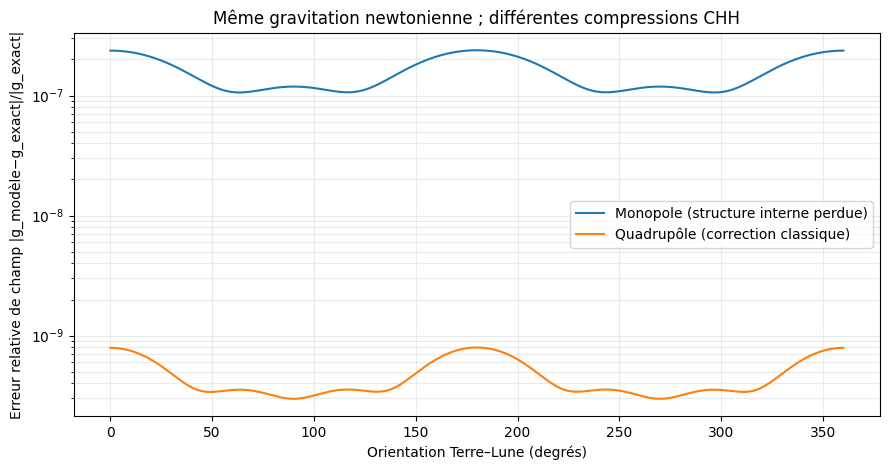

In [6]:
fig, ax=plt.subplots(figsize=(9,4.8))
ax.plot(np.rad2deg(angles),monopole_errors,label='Monopole (structure interne perdue)')
ax.plot(np.rad2deg(angles),quadrupole_errors,label='Quadrupôle (correction classique)')
ax.set_yscale('log');ax.set_xlabel('Orientation Terre–Lune (degrés)')
ax.set_ylabel('Erreur relative de champ |g_modèle−g_exact|/|g_exact|')
ax.set_title('Même gravitation newtonienne ; différentes compressions CHH')
ax.legend();ax.grid(True,which='both',alpha=.25)
fig.tight_layout()
figure_path=Path('/mnt/data/GVH_CHH_Solar_Minimal_Comparison_Error_by_Orientation.png')
fig.savefig(figure_path,dpi=160)
plt.show()
audit('figure_created',figure_path.exists())

## 6. Four-level scientific verdict
- **Level 1 — CHH:** The pair can be treated hierarchically without inventing a global EOM. Retaining internal subcubes reproduces Newton's exact pairwise calculation; monopole compression loses finite-size information; a Newtonian quadrupole restores most of it.
- **Level 2 — Established physics:** Mean catalog lunar and terrestrial periods approximately follow Kepler; Mercury's leading GR perihelion shift is recovered from the standard 1PN formula.
- **Level 3 — Execution:** Automated checks, deterministic angle grid, negative controls and source parameters; no coefficients adjusted to match observations.
- **Level 4 — Physical verdict:** `PASS_MINIMAL_CHH_METHOD_COMPARISON__NO_GVH_NEW_LAW_TEST`. There is **no physically healthy, sourced, fully constrained GVH weak-field prediction** supplied by CHH-14 or ROOT22 to contrast with Newton/GR. This notebook cannot establish new physics. Next meaningful step: derive a *parameter-identified* GVH correction from a stable 4D solution, pre-register its observable and compare to JPL ephemerides with uncertainties and competing models.

**No real galactic or particle comparison claimed.**

In [7]:
out={
 'notebook':'GVH_CHH_Solar_System_Minimal_Numerical_Comparison_Gate_FAST',
 'source_type':'JPL/NASA published constants + analytically sampled geometry',
 'status':'PASS_MINIMAL_CHH_METHOD_COMPARISON__NO_GVH_NEW_LAW_TEST',
 'mean_caveat':'Approximate mean distances, not time-tagged ephemerides; no statistical validation of new physics.',
 'parameters':{'GM_sun_km3_s2':GM_sun,'GM_earth_km3_s2':GM_earth,'GM_moon_km3_s2':GM_moon,
               'r_earth_moon_km':r_EM_km,'R_sun_earth_km':R_ES_km},
 'kepler':{'Moon_pred_days':float(moon_model),'Moon_NASA_days':T_moon_days_obs,
           'Moon_error_pct':float(moon_error_pct),'Earth_pred_days':float(earth_model),
           'Earth_JPL_days':T_earth_sidereal_days,'Earth_error_pct':float(earth_error_pct)},
 'CHH_comparison':{'angles_count':len(angles),'monopole_max_rel':float(max(monopole_errors)),
                   'quadrupole_max_rel':float(max(quadrupole_errors)),
                   'monopole_mean_rel':float(np.mean(monopole_errors)),
                   'quadrupole_mean_rel':float(np.mean(quadrupole_errors)),
                   'quadrupole_max_improvement_factor':float(max(monopole_errors)/max(quadrupole_errors)),
                   'radius_scaling_ratio':float(leading_ratio),
                   'interpretation':'known Newtonian multipole effect, NOT derived GVH effect'},
 'GR_Mercury':{'GR_1PN_perihelion_arcsec_per_julian_century':float(mercury_gr_arcsec_century),
               'GVH_prediction':None,'reason':'full sourced healthy weak-field GVH EOM and unique coefficient absent'},
 'source_urls':source_urls,'upstream_SHA256':{'GVH_CHH_Conditional_Composition_and_Coefficient_Identifiability_Gate_FAST_results.json': 'd03ac84f15d337dc77c4387d4968ed6b5f6eb9d52a2135f68fd21c22cd2383fd', 'GVH_CHH_14_Full_Metric_Spin_Principal_Symbol_and_Dirac_Constraints_GATE_FAST_results.json': 'b2450149eb9904152cc1e1cd5b0b775eb122d5e3f5fe326307351fffeec21046', 'GVH_ROOT22_Healthy_Branch_and_Independent_Prediction_Gate_FAST_results.json': 'ec0d9f8f693f862f273aa72a12b5804ef814d1713c84a75e8ea99a183d5dc836', 'GVH_CHH_Protocole_Fige_v1_2026-11-18.json': '46371af5f4504fb25ba5bac26bcd73908dbb8f3f9a196be261cc444be2380ff0'},
 'gates':{'CHH_derivative_intrinsic':False,'new_GVH_physics_validated':False,
          'root22_universal_constant_validated':False,'CHH_method_benchmark':True},
 'checks':checks,'checks_total':len(checks),'checks_passed':sum(checks.values())
}
assert all(checks.values())
result_path=Path('/mnt/data/GVH_CHH_Solar_System_Minimal_Numerical_Comparison_Gate_FAST_results.json')
result_path.write_text(json.dumps(out,indent=2,ensure_ascii=False))
print('VERDICT',out['status'])
print('AUDIT',len(checks),'/',len(checks),'checks passed')

VERDICT PASS_MINIMAL_CHH_METHOD_COMPARISON__NO_GVH_NEW_LAW_TEST
AUDIT 31 / 31 checks passed
